# Bloc 3 — Patterns et anomalies (cours 3)
**Fichiers (Health, partie clinique)** : `clinical_encounters`, `clinical_notes`, `clinical_observation`, `clinical_procedures`, `patient_administration` (versions `_cleaned`).

Pour chaque fichier :
1. **Patterns** : matrice de co-occurrences, itemsets fréquents et règles d'association (Apriori, `mlxtend`) avec *support*, *confidence*, *lift* et *leverage*.
2. **Anomalies univariées** : IQR, z-score, z-score modifié.
3. **Anomalies multivariées** : DBSCAN, Isolation Forest, LOF.
4. **Discussion** : une valeur aberrante est-elle vraiment une anomalie ?

**Rappels de lecture**
- *support* = part des lignes contenant l'itemset ; *confidence* = P(conséquent | antécédent) ; *lift* = confidence / support du conséquent (>1 : association plus fréquente que le hasard) ; *leverage* = support observé − support attendu si indépendants.
- Un point « aberrant » statistiquement n'est pas forcément une erreur : il peut être rare mais légitime (un vrai cas clinique) ou un artefact de génération. On le discute à chaque fois.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_style('whitegrid')
chemin = 'cleaned/'

## 0. Fonctions utilitaires (réutilisées pour les 5 fichiers)

In [4]:
# ---------- PATTERNS : co-occurrences + Apriori + règles ----------
def patterns(df_cat, min_support, nom, min_conf=0.6, min_lift=1.2, top=12, n_items_heatmap=20):
    # One-hot de chaque modalité ("variable=valeur") : une ligne = un panier d'items
    onehot = pd.get_dummies(df_cat.astype(str), prefix_sep='=', dtype=bool)

    # 1) Matrice de co-occurrences (nb de lignes où deux items apparaissent ensemble)
    frequents = onehot.mean().sort_values(ascending=False).head(n_items_heatmap).index
    X = onehot[frequents].astype(int)
    cooc = X.T @ X
    plt.figure(figsize=(11, 9))
    sns.heatmap(cooc, cmap='Blues', annot=len(frequents) <= 14, fmt='d', cbar_kws={'label': 'nombre de co-occurrences'})
    plt.title(f'Matrice de co-occurrences — {nom} ({len(frequents)} items les plus fréquents)')
    plt.tight_layout(); plt.show()

    # 2) Itemsets fréquents (Apriori)
    freq = apriori(onehot, min_support=min_support, use_colnames=True)
    freq['taille'] = freq['itemsets'].apply(len)
    print(f'{len(freq)} itemsets fréquents (support >= {min_support}) dont {(freq.taille >= 2).sum()} de taille >= 2')

    # 3) Règles d'association (compatibilité des versions de mlxtend : num_itemsets requis dans les plus récentes)
    try:
        regles = association_rules(freq, num_itemsets=len(onehot), metric='lift', min_threshold=1.0)
    except TypeError:
        regles = association_rules(freq, metric='lift', min_threshold=1.0)
    regles = regles[(regles.confidence >= min_conf) & (regles.lift >= min_lift)].copy()
    regles['antecedents'] = regles['antecedents'].apply(lambda s: ' & '.join(sorted(s)))
    regles['consequents'] = regles['consequents'].apply(lambda s: ' & '.join(sorted(s)))
    regles = regles.sort_values(['lift', 'confidence'], ascending=False).reset_index(drop=True)
    print(f'{len(regles)} règles avec confidence >= {min_conf} et lift >= {min_lift}')
    cols = ['antecedents', 'consequents', 'support', 'confidence', 'lift', 'leverage']
    display(regles[cols].head(top).round(3))

    # Beaucoup de règles ont confidence = 1 : ce sont des dépendances « mécaniques » entre variables.
    # On affiche aussi celles qui ne sont PAS déterministes (confidence < 0.99), souvent plus informatives.
    nd = regles[regles.confidence < 0.99]
    print(f'dont {len(nd)} règles non déterministes (confidence < 0.99) :')
    display(nd[cols].head(top).round(3))

    # 4) Visualisation des règles : support vs confidence, couleur = lift
    if len(regles) > 0:
        plt.figure(figsize=(8, 5))
        sc = plt.scatter(regles.support, regles.confidence, c=regles.lift, cmap='viridis', s=40 + 300 * regles.leverage.clip(lower=0), alpha=0.8, edgecolor='k')
        plt.colorbar(sc, label='lift'); plt.xlabel('support'); plt.ylabel('confidence')
        plt.title(f'Règles d\'association — {nom} (taille = leverage)')
        plt.tight_layout(); plt.show()
    return onehot, freq, regles


# ---------- ANOMALIES UNIVARIEES : IQR, z-score, z-score modifié ----------
def anomalies_univariees(s, nom, unite=''):
    s = s.dropna().astype(float)
    # IQR : hors de [Q1 - 1.5 IQR ; Q3 + 1.5 IQR]
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    f_iqr = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    # z-score classique : |z| > 3 (sensible aux valeurs extrêmes, car moyenne et écart-type en dépendent)
    z = (s - s.mean()) / s.std()
    f_z = z.abs() > 3
    # z-score modifié (Iglewicz-Hoaglin) : 0.6745 (x - médiane) / MAD, seuil 3.5 (robuste)
    med = s.median(); mad = (s - med).abs().median()
    if mad == 0:   # MAD nul si plus de la moitié des valeurs sont identiques : repli sur l'écart moyen absolu
        zm = (s - med) / (1.253314 * (s - med).abs().mean()); note = ' (MAD = 0 : repli sur l\'écart moyen absolu)'
    else:
        zm = 0.6745 * (s - med) / mad; note = ''
    f_zm = zm.abs() > 3.5
    res = pd.DataFrame({'valeur': s, 'z': z, 'z_modifie': zm, 'IQR': f_iqr, 'flag_z': f_z, 'flag_zm': f_zm})
    print(f'{nom} : n={len(s)}, médiane={med:.2f}, Q1={q1:.2f}, Q3={q3:.2f}, min={s.min():.2f}, max={s.max():.2f}')
    print(f'  IQR : {f_iqr.sum()} | z-score (|z|>3) : {f_z.sum()} | z modifié (>3.5) : {f_zm.sum()}{note}')
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    sns.boxplot(x=s, ax=ax[0], color='lightsteelblue', showfliers=False)
    sns.stripplot(x=s[~f_iqr], ax=ax[0], color='grey', size=2, alpha=0.4)
    sns.stripplot(x=s[f_iqr], ax=ax[0], color='crimson', size=4)
    ax[0].set_title(f'{nom} — boxplot (rouge = hors IQR)'); ax[0].set_xlabel(unite)
    ax[1].hist(s, bins=40, color='lightsteelblue', edgecolor='white')
    for v in s[f_zm].unique()[:50]:
        ax[1].axvline(v, color='crimson', alpha=0.3)
    ax[1].set_yscale('log'); ax[1].set_title('Histogramme (échelle log ; rouge = z modifié)'); ax[1].set_xlabel(unite)
    plt.tight_layout(); plt.show()
    return res


# ---------- ANOMALIES MULTIVARIEES : DBSCAN, Isolation Forest, LOF ----------
def anomalies_multivariees(X, nom, contamination=0.02, n_voisins=20, min_samples=5):
    # Variables numériques continues : ici la standardisation est légitime (contrairement aux one-hot du bloc 2)
    Xs = StandardScaler().fit_transform(X)
    iso = IsolationForest(contamination=contamination, random_state=42).fit(Xs)
    f_if = iso.predict(Xs) == -1; s_if = -iso.score_samples(Xs)
    lof = LocalOutlierFactor(n_neighbors=min(n_voisins, len(Xs) - 1), contamination=contamination)
    f_lof = lof.fit_predict(Xs) == -1; s_lof = -lof.negative_outlier_factor_
    # DBSCAN : eps lu sur la courbe des distances au min_samples-ième voisin (on prend le quantile 1 - contamination)
    d, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xs).kneighbors(Xs)
    kdist = np.sort(d[:, -1])
    eps = max(np.quantile(kdist, 1 - contamination), 0.1)
    f_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xs) == -1
    res = pd.DataFrame({'IsolationForest': f_if, 'LOF': f_lof, 'DBSCAN': f_db, 'score_if': s_if, 'score_lof': s_lof}, index=X.index)
    res['nb_methodes'] = res[['IsolationForest', 'LOF', 'DBSCAN']].sum(axis=1)
    print(f'{nom} : n={len(X)} | Isolation Forest : {f_if.sum()} | LOF : {f_lof.sum()} | DBSCAN (eps={eps:.2f}, min_samples={min_samples}) : {f_db.sum()}')
    print('  Flaggés par >= 2 méthodes :', (res.nb_methodes >= 2).sum(), '| par les 3 :', (res.nb_methodes == 3).sum())
    # Visualisation : projection PCA 2D (ou les 2 variables telles quelles), couleur = nombre de méthodes qui signalent le point
    P = PCA(n_components=2).fit_transform(Xs) if Xs.shape[1] > 2 else Xs
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    ax[0].plot(kdist, color='steelblue'); ax[0].axhline(eps, color='crimson', ls='--', label=f'eps = {eps:.2f}')
    ax[0].set_title(f'Distance au {min_samples}e voisin (choix de eps pour DBSCAN)'); ax[0].set_xlabel('points triés'); ax[0].legend()
    couleurs = {0: 'lightgrey', 1: 'gold', 2: 'darkorange', 3: 'crimson'}
    for k in [0, 1, 2, 3]:
        m = (res.nb_methodes == k).values
        if m.any():
            ax[1].scatter(P[m, 0], P[m, 1], c=couleurs[k], s=14 if k == 0 else 45, alpha=0.5 if k == 0 else 0.95, edgecolor='k' if k else 'none', linewidth=0.4, label=f'{k} méthode(s) ({m.sum()})')
    ax[1].legend(title='Signalé par'); ax[1].set_title(f'{nom} — anomalies multivariées')
    ax[1].set_xlabel('PCA 1' if Xs.shape[1] > 2 else X.columns[0]); ax[1].set_ylabel('PCA 2' if Xs.shape[1] > 2 else X.columns[1])
    plt.tight_layout(); plt.show()
    return res

---
## 1. `clinical_encounters`

In [5]:
enc = pd.read_csv(chemin + 'clinical_encounters_cleaned.csv', parse_dates=['encounter_start', 'encounter_end', 'follow_up_date'])
enc['duree_min'] = (enc.encounter_end - enc.encounter_start).dt.total_seconds() / 60
enc['delai_suivi_j'] = (enc.follow_up_date - enc.encounter_end).dt.days
enc['heure_debut'] = enc.encounter_start.dt.hour + enc.encounter_start.dt.minute / 60
print(enc.shape)
enc[['duree_min', 'delai_suivi_j', 'heure_debut']].describe().round(2)

(1067, 15)


,duree_min,delai_suivi_j,heure_debut
count,1067.00,827.00,1067.00
mean,87.67,387.39,10.86
std,34.58,172.70,1.36
min,50.00,8.00,8.50
25%,66.00,293.00,9.25
50%,82.00,395.00,11.25
75%,101.00,494.50,12.25
max,240.00,1180.00,14.25


### 1.1 Patterns (Apriori)
Items = modalités des variables catégorielles (identifiants, licences et dates exclus, comme au bloc 2).

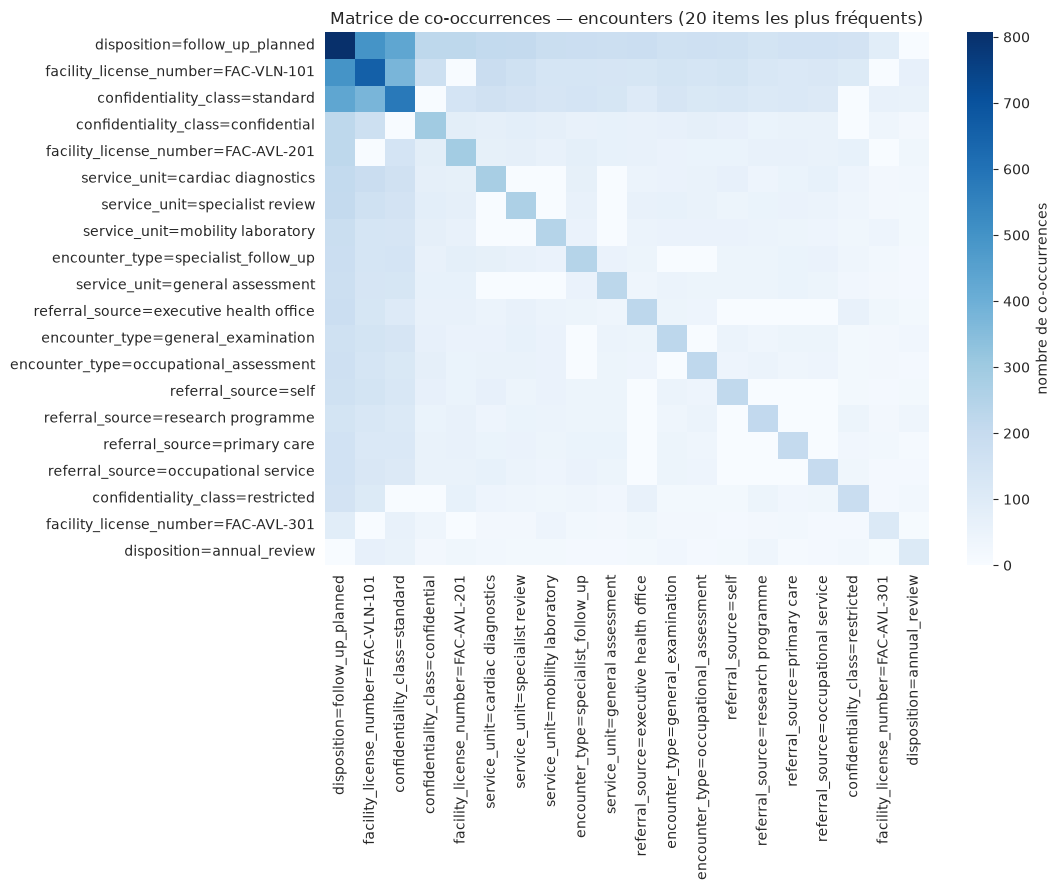

179 itemsets fréquents (support >= 0.05) dont 154 de taille >= 2
2 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,confidentiality_class=restricted & referral_so...,disposition=follow_up_planned,0.052,0.933,1.234,0.010
1,confidentiality_class=standard & disposition=f...,facility_license_number=FAC-VLN-101,0.081,0.741,1.202,0.014


dont 2 règles non déterministes (confidence < 0.99) :


,antecedents,consequents,support,confidence,lift,leverage
0,confidentiality_class=restricted & referral_so...,disposition=follow_up_planned,0.052,0.933,1.234,0.010
1,confidentiality_class=standard & disposition=f...,facility_license_number=FAC-VLN-101,0.081,0.741,1.202,0.014


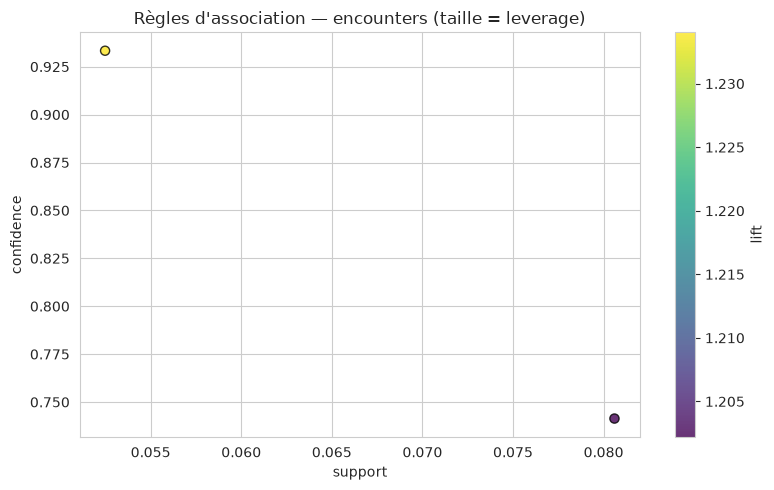

In [6]:
cat_enc = ['encounter_type', 'referral_source', 'service_unit', 'disposition', 'confidentiality_class', 'facility_license_number']
onehot_enc, freq_enc, regles_enc = patterns(enc[cat_enc], min_support=0.05, nom='encounters')

**Interprétation :** 179 itemsets fréquents (support ≥ 5 %), mais seulement **2 règles** passent les seuils (confidence ≥ 0.6, lift ≥ 1.2) et leur lift reste proche de 1 (1.20 et 1.23) : les consultations ne forment pas de véritables « paniers » typés.
- `confidentiality_class=restricted` & `referral_source=executive health office` ⇒ `disposition=follow_up_planned` (support 0.052, confidence 0.93, lift 1.23).
- `standard` & `follow_up_planned` & `cardiac diagnostics` ⇒ `FAC-VLN-101` (support 0.081, confidence 0.74, lift 1.20).

La matrice de co-occurrences est dominée par les modalités les plus fréquentes (`follow_up_planned` : 807 consultations sur 1067 ; `FAC-VLN-101` ; `standard`) : elle compte des effectifs, pas des associations. C'est le **lift** qui dit si deux modalités vont ensemble plus que par hasard. Cela confirme le bloc 2 (silhouette 0.16 : pas de groupes naturels).

### 1.2 Anomalies univariées
Deux variables numériques construites à partir des dates : la **durée** de la consultation et le **délai** jusqu'à la date de suivi.

Durée de consultation : n=1067, médiane=82.00, Q1=66.00, Q3=101.00, min=50.00, max=240.00
  IQR : 50 | z-score (|z|>3) : 30 | z modifié (>3.5) : 50


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


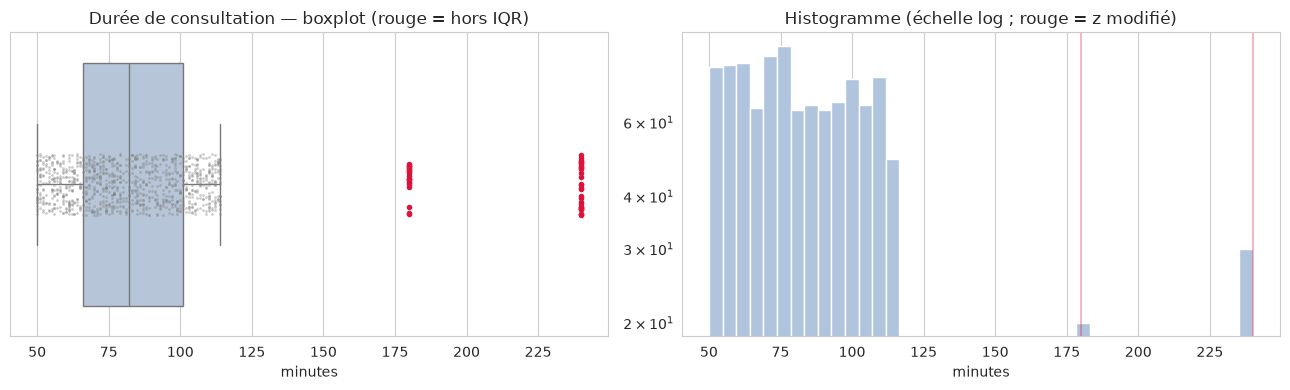

Délai avant suivi : n=827, médiane=395.00, Q1=293.00, Q3=494.50, min=8.00, max=1180.00
  IQR : 9 | z-score (|z|>3) : 2 | z modifié (>3.5) : 2


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


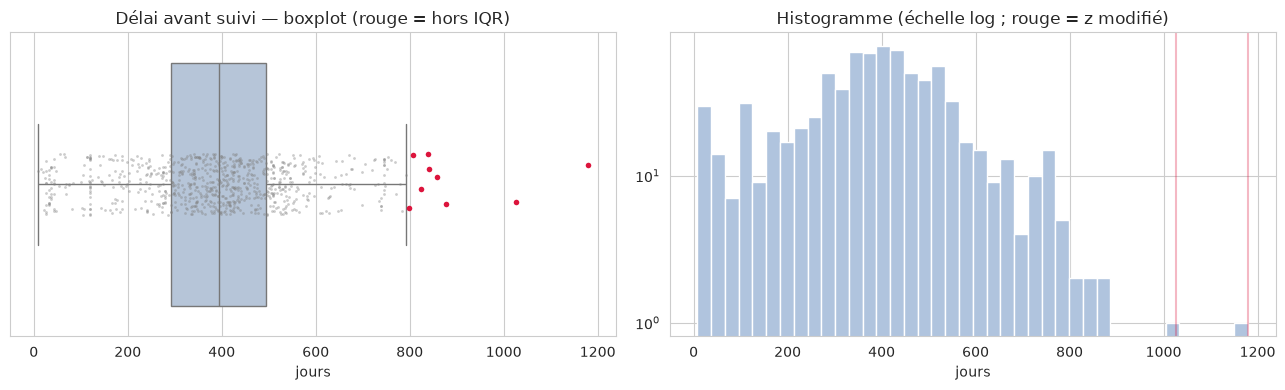

,encounter_number,encounter_type,duree_min,confidentiality_class
1036,ENC-001037,specialist_procedure,240.0,restricted
1035,ENC-001036,specialist_procedure,240.0,restricted
1038,ENC-001039,specialist_procedure,240.0,restricted
1037,ENC-001038,specialist_procedure,240.0,restricted
1034,ENC-001035,specialist_procedure,240.0,restricted
1033,ENC-001034,specialist_procedure,240.0,restricted
1031,ENC-001032,specialist_procedure,240.0,restricted
1032,ENC-001033,specialist_procedure,240.0,restricted
1024,ENC-001025,specialist_procedure,240.0,restricted
1023,ENC-001024,specialist_procedure,240.0,restricted


In [7]:
r_duree = anomalies_univariees(enc.duree_min, 'Durée de consultation', 'minutes')
r_suivi = anomalies_univariees(enc.delai_suivi_j, 'Délai avant suivi', 'jours')
enc.loc[r_duree[r_duree.IQR].index, ['encounter_number', 'encounter_type', 'duree_min', 'confidentiality_class']].sort_values('duree_min').tail(10)

In [8]:
# Les consultations hors IQR sont-elles concentrées sur un type de consultation ?
tmp = enc.loc[r_duree.index].assign(hors_IQR=r_duree.IQR)
pd.crosstab(tmp.encounter_type, tmp.hors_IQR)

hors_IQR,False,True
encounter_type,,
cardiac_assessment,76,0
executive_health_review,98,0
general_examination,226,0
mobility_assessment,80,0
occupational_assessment,218,0
ocular_assessment,44,0
research_procedure,0,20
specialist_follow_up,243,0
specialist_procedure,0,30


### 1.3 Anomalies multivariées

Encounters : n=827 | Isolation Forest : 14 | LOF : 17 | DBSCAN (eps=0.67, min_samples=5) : 10
  Flaggés par >= 2 méthodes : 3 | par les 3 : 0


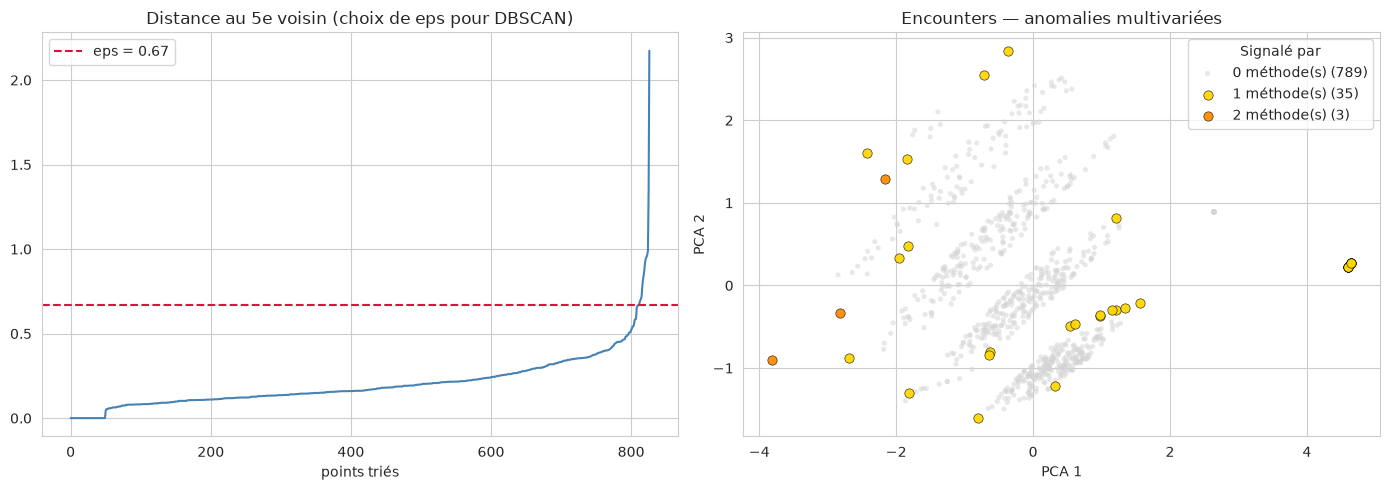

,encounter_number,encounter_type,duree_min,delai_suivi_j,heure_debut,nb_methodes,score_if
1032,ENC-001033,specialist_procedure,240.0,27.0,8.5,1,0.705331
1020,ENC-001021,specialist_procedure,240.0,27.0,8.5,1,0.705331
1028,ENC-001029,specialist_procedure,240.0,27.0,8.5,1,0.705331
1044,ENC-001045,specialist_procedure,240.0,27.0,8.5,1,0.705331
1036,ENC-001037,specialist_procedure,240.0,27.0,8.5,1,0.705331
1040,ENC-001041,specialist_procedure,240.0,27.0,8.5,1,0.705331
1024,ENC-001025,specialist_procedure,240.0,27.0,8.5,1,0.705331
1031,ENC-001032,specialist_procedure,240.0,42.0,8.5,1,0.689272
1039,ENC-001040,specialist_procedure,240.0,42.0,8.5,1,0.689272
1027,ENC-001028,specialist_procedure,240.0,42.0,8.5,1,0.689272


In [9]:
X_enc = enc[['duree_min', 'delai_suivi_j', 'heure_debut']].dropna()
m_enc = anomalies_multivariees(X_enc, 'Encounters', contamination=0.02)
enc.loc[m_enc.index, ['encounter_number', 'encounter_type', 'duree_min', 'delai_suivi_j', 'heure_debut']].join(m_enc[['nb_methodes', 'score_if']]).sort_values('score_if', ascending=False).head(10)

In [10]:
# Quels types de consultation sont signalés par chaque méthode ? (n = effectif du type dans X_enc)
tmp = enc.loc[m_enc.index, ['encounter_type']].join(m_enc[['IsolationForest', 'LOF', 'DBSCAN']])
tmp.groupby('encounter_type')[['IsolationForest', 'LOF', 'DBSCAN']].sum().join(tmp.encounter_type.value_counts().rename('n')).sort_values('n')

,IsolationForest,LOF,DBSCAN,n
encounter_type,,,,
research_procedure,0,0,0,20
technical_repeat,0,0,0,24
specialist_procedure,14,0,0,30
ocular_assessment,0,0,0,33
cardiac_assessment,0,0,0,61
mobility_assessment,0,2,1,65
executive_health_review,0,12,6,78
general_examination,0,1,0,164
occupational_assessment,0,1,0,170


**Interprétation :**
- **Durée.** Toutes les consultations durent 50 à 114 min, sauf **20 `research_procedure` (toujours 180 min)** et **30 `specialist_procedure` (toujours 240 min)**. L'IQR et le z-score modifié signalent exactement ces 50 consultations ; le z-score classique n'en voit que 30 (les 240 min), car les 180 min restent sous 3 écarts-types.
- **Délai avant suivi** (827 consultations ont une date de suivi ; les 240 autres sont `annual_review`, `discharged` ou `follow_up_as_needed`) : 9 valeurs hors IQR, 2 par z-score (ENC-000065, 1 180 jours, et ENC-000080, 1 026 jours : `executive_health_review` des patients PAT-31044 et PAT-31074).
- **Multivarié** (durée, délai de suivi, heure de début ; 827 lignes) : Isolation Forest 14, LOF 17, DBSCAN 10 ; seules 3 consultations sont signalées par au moins deux méthodes, aucune par les trois. Les scores les plus élevés sont tous des `specialist_procedure`.

**Est-ce vraiment une anomalie ?** Statistiquement oui, mais ce ne sont **pas des erreurs** : la durée est une constante propre au type de consultation (180 ou 240 min, sans aucune variation), et ces 50 consultations sont les mêmes que les clusters isolés du bloc 2 (consultations de recherche et spécialisées, toutes restreintes). C'est un **indice de structure**, pas du bruit : à relier aux 50 procédures `MRP-42` (voir la section 4). Les délais de suivi de 3 ans sont plausibles mais rares : à garder comme anomalie légère.

---
## 2. `clinical_notes`
Seulement 30 lignes : on applique les mêmes méthodes mais les résultats sont indicatifs. Le texte (`text`, `title`) est exclu ici (bloc 6).

In [11]:
notes = pd.read_csv(chemin + 'clinical_notes_cleaned.csv', parse_dates=['document_date'])
notes['nb_mots'] = notes.text.str.split().str.len()
notes = notes.merge(enc[['encounter_number', 'encounter_start']], on='encounter_number', how='left')
notes['delai_note_j'] = (notes.document_date - notes.encounter_start.dt.normalize()).dt.days
print(notes.shape)
notes[['nb_mots', 'delai_note_j']].describe().round(2)

(30, 13)


,nb_mots,delai_note_j
count,30.00,30.00
mean,179.23,481.87
std,47.96,885.24
min,122.00,-1249.00
25%,125.00,-41.00
50%,180.00,292.50
75%,184.00,956.00
max,269.00,2670.00


### 2.1 Patterns (Apriori)

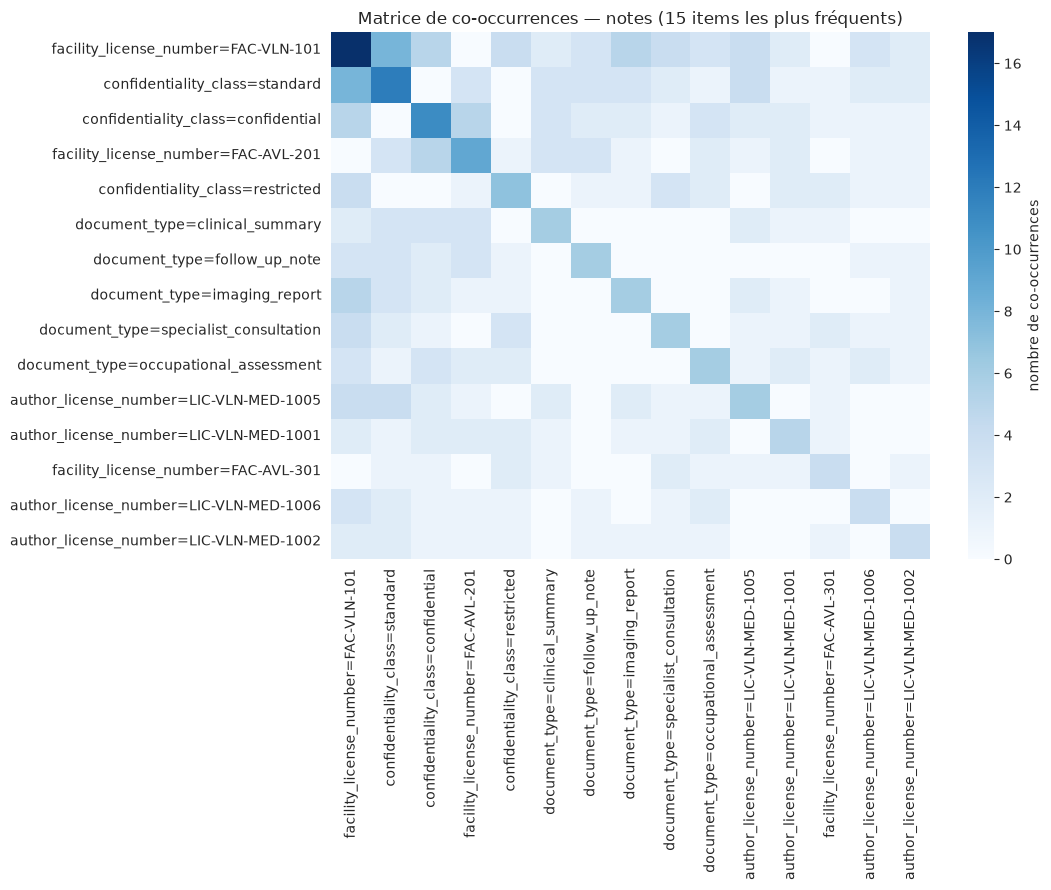

16 itemsets fréquents (support >= 0.15) dont 4 de taille >= 2
1 règles avec confidence >= 0.7 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,document_type=imaging_report,facility_license_number=FAC-VLN-101,0.167,0.833,1.471,0.053


dont 1 règles non déterministes (confidence < 0.99) :


,antecedents,consequents,support,confidence,lift,leverage
0,document_type=imaging_report,facility_license_number=FAC-VLN-101,0.167,0.833,1.471,0.053


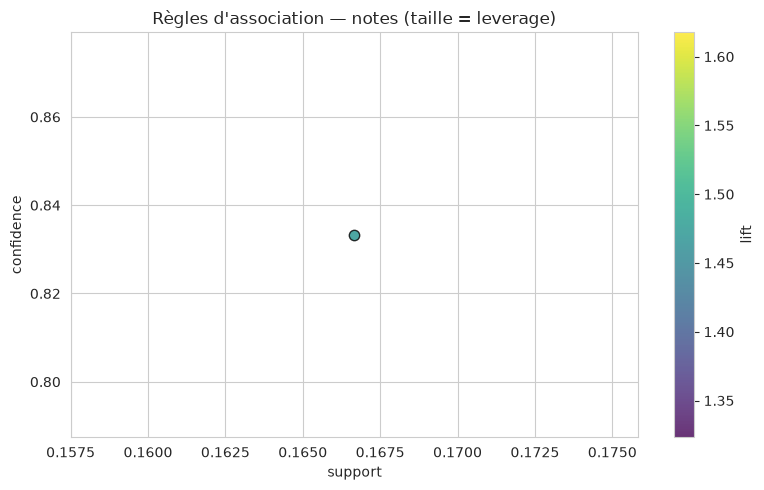

In [12]:
cat_notes = ['document_type', 'confidentiality_class', 'facility_license_number', 'author_license_number']
onehot_notes, freq_notes, regles_notes = patterns(notes[cat_notes], min_support=0.15, nom='notes', min_conf=0.7, min_lift=1.2, n_items_heatmap=15)

**Interprétation :** avec 30 notes, les résultats sont fragiles (une modalité à 15 % de support = 5 notes). Une seule règle : `document_type=imaging_report` ⇒ `FAC-VLN-101` (support 0.167, confidence 0.83, lift 1.47). À ne pas généraliser : c'est un effet de petit effectif.

### 2.2 Anomalies univariées

Longueur des notes : n=30, médiane=180.00, Q1=125.00, Q3=184.00, min=122.00, max=269.00
  IQR : 0 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


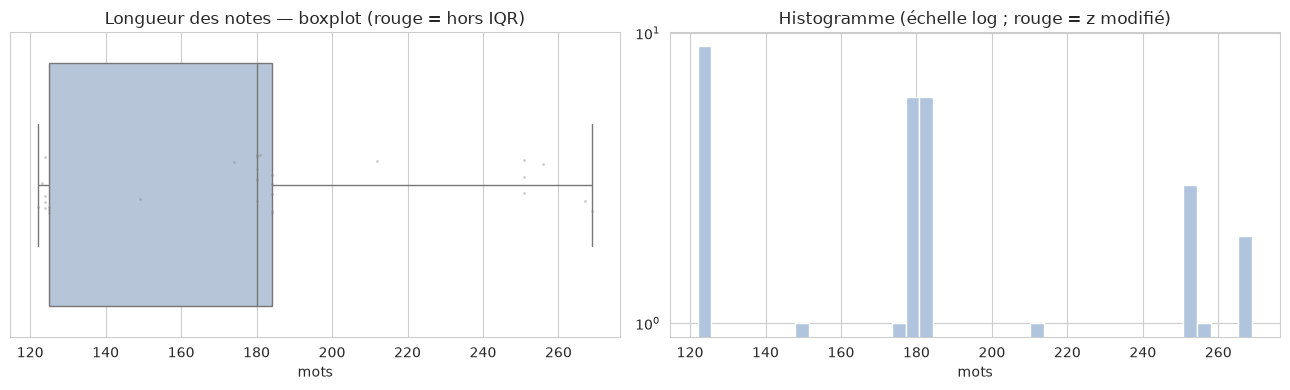

Délai consultation → note : n=30, médiane=292.50, Q1=-41.00, Q3=956.00, min=-1249.00, max=2670.00
  IQR : 1 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


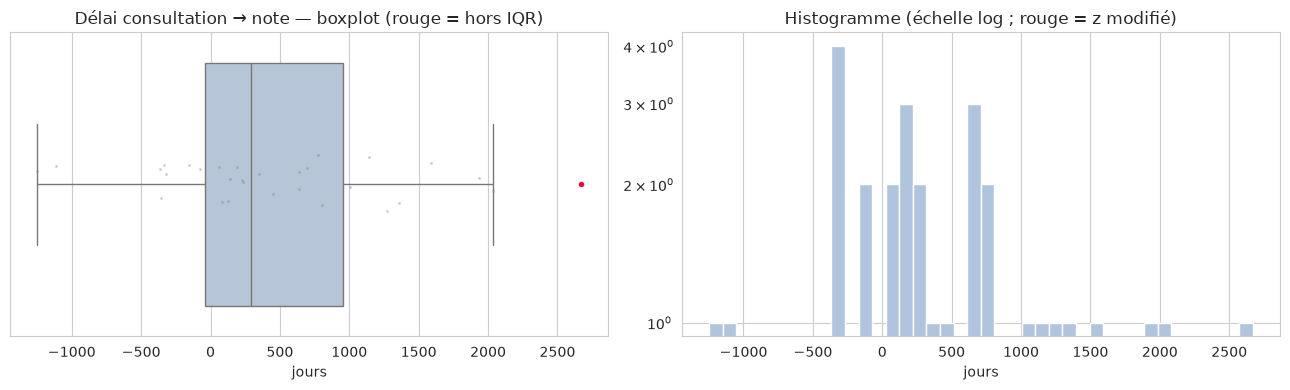

,document_id,document_type,nb_mots,delai_note_j,confidentiality_class
10,CLN-510126,imaging_report,149,2670,confidential


In [13]:
r_mots = anomalies_univariees(notes.nb_mots, 'Longueur des notes', 'mots')
r_delai = anomalies_univariees(notes.delai_note_j, 'Délai consultation → note', 'jours')
notes.loc[r_mots[r_mots.IQR | r_mots.flag_zm].index.union(r_delai[r_delai.IQR | r_delai.flag_zm].index), ['document_id', 'document_type', 'nb_mots', 'delai_note_j', 'confidentiality_class']]

In [14]:
# Cohérence temporelle : une note ne devrait pas être datée AVANT la consultation à laquelle elle se rattache
avant = notes[notes.delai_note_j < 0]
print(len(avant), 'notes sur', len(notes), 'sont datées avant leur consultation')
avant[['document_id', 'document_type', 'patient_number', 'encounter_number', 'document_date', 'encounter_start', 'delai_note_j']].sort_values('delai_note_j')

8 notes sur 30 sont datées avant leur consultation


,document_id,document_type,patient_number,encounter_number,document_date,encounter_start,delai_note_j
11,CLN-510129,imaging_report,PAT-31136,ENC-000105,2018-05-03,2021-10-03 09:15:00,-1249
19,CLN-510038,follow_up_note,PAT-31169,ENC-000209,2018-09-05,2021-09-21 12:15:00,-1112
20,CLN-510058,follow_up_note,PAT-31126,ENC-000222,2021-02-12,2022-02-13 10:15:00,-366
14,CLN-510118,imaging_report,PAT-31190,ENC-000144,2019-08-24,2020-08-18 12:15:00,-360
25,CLN-510093,occupational_assessment,PAT-31222,ENC-000287,2020-03-20,2021-02-15 11:15:00,-332
15,CLN-510039,specialist_consultation,PAT-31103,ENC-000157,2022-01-04,2022-11-21 12:15:00,-321
26,CLN-510036,occupational_assessment,PAT-31171,ENC-000300,2023-08-27,2024-01-28 11:15:00,-154
1,CLN-510055,specialist_consultation,PAT-31115,ENC-000016,2024-01-19,2024-04-03 13:15:00,-75


### 2.3 Anomalies multivariées

Notes : n=30 | Isolation Forest : 3 | LOF : 3 | DBSCAN (eps=0.99, min_samples=3) : 0
  Flaggés par >= 2 méthodes : 2 | par les 3 : 0


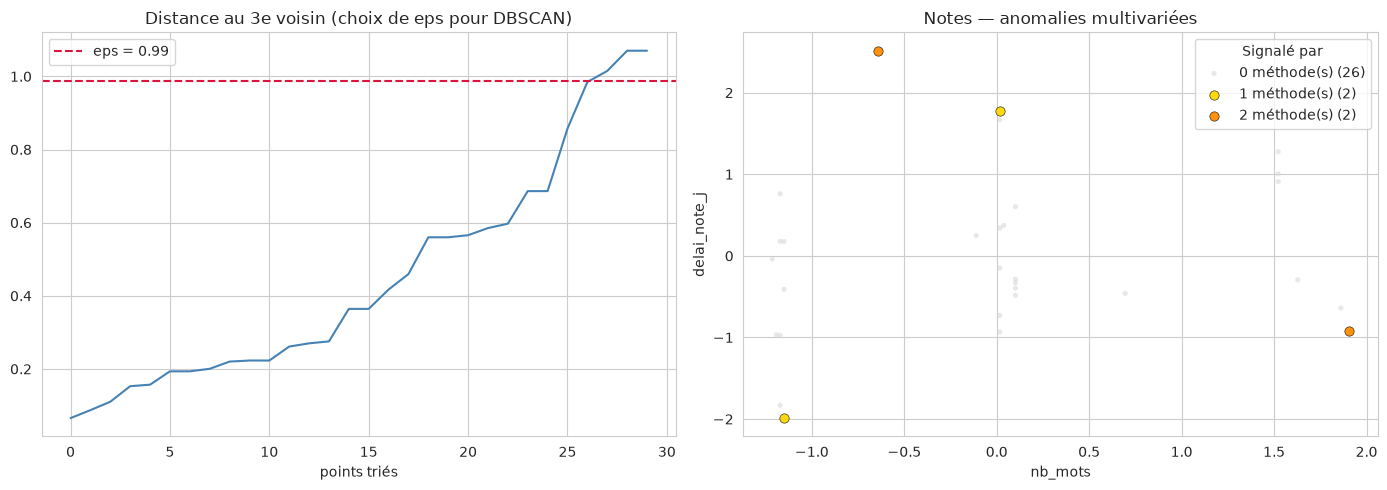

,document_id,document_type,nb_mots,delai_note_j,nb_methodes,score_if
10,CLN-510126,imaging_report,149,2670,2,0.669119
11,CLN-510129,imaging_report,125,-1249,1,0.605162
15,CLN-510039,specialist_consultation,269,-321,2,0.578841
16,CLN-510106,specialist_consultation,251,1592,0,0.578199
19,CLN-510038,follow_up_note,124,-1112,0,0.562197
1,CLN-510055,specialist_consultation,267,-75,0,0.557890


In [15]:
X_notes = notes[['nb_mots', 'delai_note_j']].dropna()
m_notes = anomalies_multivariees(X_notes, 'Notes', contamination=0.1, n_voisins=5, min_samples=3)
notes.loc[m_notes.index, ['document_id', 'document_type', 'nb_mots', 'delai_note_j']].join(m_notes[['nb_methodes', 'score_if']]).sort_values('score_if', ascending=False).head(6)

**Interprétation :**
- **Longueur** : aucune anomalie (122 à 269 mots, IQR/z-score/z modifié = 0). Les notes ont des longueurs homogènes.
- **Délai consultation → note** : médiane de 292 jours, étendue de −1 249 à +2 670 jours. **8 notes sur 30 sont datées avant la consultation à laquelle elles sont rattachées** (de −75 à −1 249 jours ; les plus extrêmes : CLN-510129 à −1 249 j et CLN-510038 à −1 112 j). À l'autre bout, CLN-510126 (PAT-31099, `imaging_report`) est datée 2 670 jours (plus de 7 ans) après sa consultation : c'est la seule valeur hors IQR.
- **Multivarié** : Isolation Forest 3, LOF 3, DBSCAN 0 ; CLN-510126 et CLN-510039 sont signalées par 2 méthodes.

**Est-ce vraiment une anomalie ?** Une note rédigée avant la consultation est **logiquement impossible** : soit le rattachement `encounter_number` est approximatif, soit la date du document est un artefact de génération (les délais s'étalent sur plusieurs années dans les deux sens, sans rapport avec le type de note). Comme les notes sont peu nombreuses et que ce problème touche 27 % d'entre elles, on le note comme **incohérence de données** à signaler dans le tableau d'indices, sans en tirer d'hypothèse sur les patients. À relire avec le contenu (bloc 6).

---
## 3. `clinical_observation`

In [16]:
obs = pd.read_csv(chemin + 'clinical_observation_cleaned.csv', parse_dates=['observation_time'])
print(obs.shape)
obs.groupby('observation_code').numeric_value.agg(['count', 'mean', 'std', 'min', 'max']).round(2).head(10)

(17734, 14)


,count,mean,std,min,max
observation_code,,,,,
agecond,240,0.98,0.91,0.0,4.0
apical,1017,77.08,12.12,42.0,106.7
balance,947,76.40,12.96,38.9,100.0
binocoord,0,NaN,NaN,NaN,NaN
bioage,934,49.70,16.28,11.5,88.3
cammatch,240,89.38,9.36,40.6,100.0
cardout,941,5.47,1.01,3.0,9.6
cognitive,948,86.32,8.59,57.2,100.0
cvrisk,240,42.23,12.06,6.4,76.9


### 3.1 Patterns (Apriori)
`device_reference` et `assessor_license_number` sont gardés (peu de modalités) ; `unit` est exclue (elle se déduit à 100 % de `observation_code`, ce qui ne produirait que des règles triviales) et `quality_code` n'a qu'une valeur (`acceptable`).

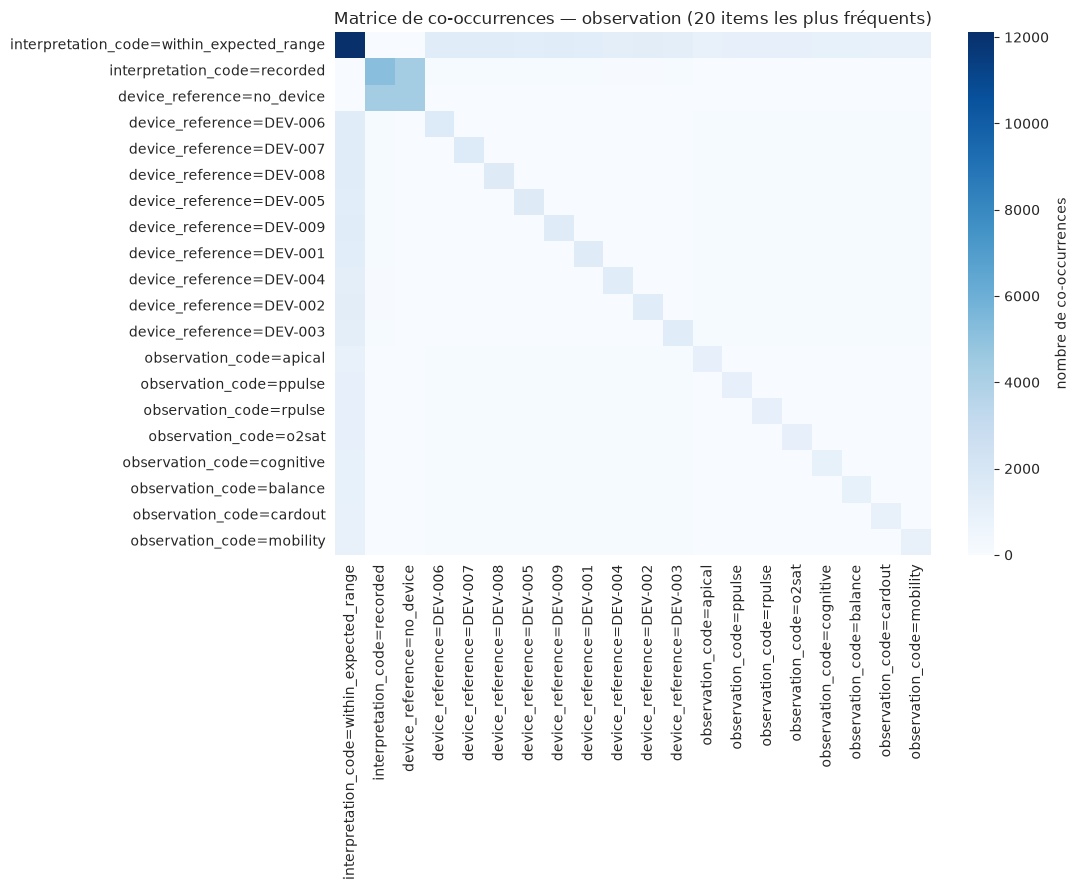

50 itemsets fréquents (support >= 0.02) dont 24 de taille >= 2
25 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,device_reference=no_device,interpretation_code=recorded,0.244,0.999,3.415,0.172
1,interpretation_code=recorded,device_reference=no_device,0.244,0.833,3.415,0.172
2,observation_code=ocular,interpretation_code=recorded,0.049,0.954,3.261,0.034
3,observation_code=balance,interpretation_code=within_expected_range,0.053,1.000,1.464,0.017
4,observation_code=bioage,interpretation_code=within_expected_range,0.053,1.000,1.464,0.017
5,observation_code=cardout,interpretation_code=within_expected_range,0.053,1.000,1.464,0.017
6,observation_code=cognitive,interpretation_code=within_expected_range,0.053,1.000,1.464,0.017
7,observation_code=inflam,interpretation_code=within_expected_range,0.052,1.000,1.464,0.017
8,observation_code=mobility,interpretation_code=within_expected_range,0.053,1.000,1.464,0.017
9,observation_code=o2sat,interpretation_code=within_expected_range,0.057,1.000,1.464,0.018


dont 15 règles non déterministes (confidence < 0.99) :


,antecedents,consequents,support,confidence,lift,leverage
1,interpretation_code=recorded,device_reference=no_device,0.244,0.833,3.415,0.172
2,observation_code=ocular,interpretation_code=recorded,0.049,0.954,3.261,0.034
12,observation_code=thorvib,interpretation_code=within_expected_range,0.048,0.916,1.342,0.012
13,device_reference=DEV-009,interpretation_code=within_expected_range,0.078,0.912,1.335,0.019
14,device_reference=DEV-002,interpretation_code=within_expected_range,0.072,0.911,1.334,0.018
15,observation_code=thorpeak,interpretation_code=within_expected_range,0.048,0.911,1.334,0.012
16,device_reference=DEV-001,interpretation_code=within_expected_range,0.075,0.907,1.328,0.019
17,device_reference=DEV-008,interpretation_code=within_expected_range,0.079,0.905,1.325,0.019
18,device_reference=DEV-004,interpretation_code=within_expected_range,0.072,0.903,1.322,0.018
19,device_reference=DEV-003,interpretation_code=within_expected_range,0.071,0.900,1.318,0.017


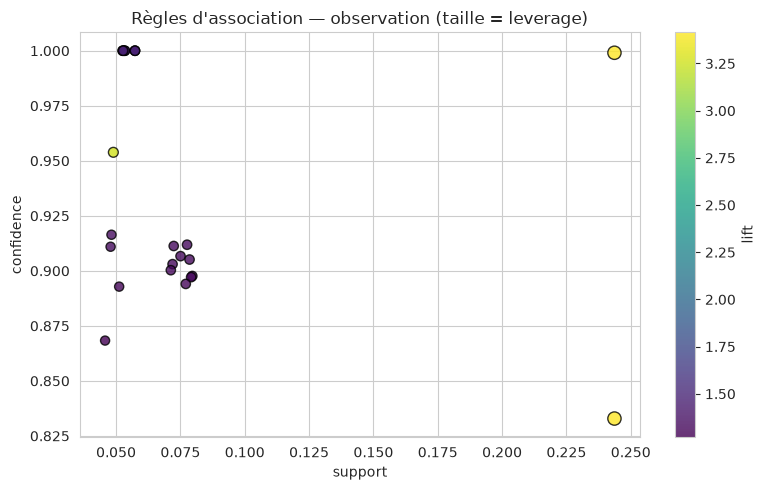

In [17]:
cat_obs = ['observation_code', 'interpretation_code', 'device_reference']
onehot_obs, freq_obs, regles_obs = patterns(obs[cat_obs], min_support=0.02, nom='observation', min_conf=0.6, min_lift=1.2)

**Interprétation :** 121 itemsets fréquents, 116 règles (confidence ≥ 0.6, lift ≥ 1.2). Les règles de confidence 1 sont mécaniques : chaque mesure quantitative (`bioage`, `cardout`, `mobility`...) est toujours `within_expected_range` dans les itemsets fréquents. Les règles non déterministes sont plus parlantes :
- `interpretation_code=recorded` ⇒ `device_reference=no_device` (support 0.244, confidence 0.83, lift 3.41) : les observations qualitatives « recorded » sont surtout faites sans appareil.
- `observation_code=ocular` ⇒ `interpretation_code=recorded` (confidence 0.95, lift 3.26).
- Les appareils DEV-001 à DEV-009 ⇒ `within_expected_range` (confidence ≈ 0.90, lift ≈ 1.3) : l'appareil n'explique rien, c'est l'effet inverse de `recorded` (qui n'a pas d'appareil).

Les cas rares (`review` 326 lignes, `discordant` 109) tombent sous le support minimal de 2 % : Apriori ne les voit pas, d'où l'intérêt des méthodes d'anomalies ci-dessous.

### 3.2 Anomalies univariées
Une valeur n'a de sens qu'**au sein de son type de mesure** (un pouls de 70 et un taux d'inflammation de 0,4 ne se comparent pas) : on applique donc IQR et z-score modifié **par `observation_code`**, puis on détaille la fréquence apicale.

In [18]:
resume = []
for code_obs, g in obs.dropna(subset=['numeric_value']).groupby('observation_code'):
    s = g.numeric_value
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    f_iqr = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    f_z = ((s - s.mean()).abs() / s.std() > 3).sum()
    mad = (s - s.median()).abs().median()
    f_zm = (0.6745 * (s - s.median()).abs() / mad > 3.5).sum() if mad > 0 else np.nan
    resume.append((code_obs, len(s), f_iqr, f_z, f_zm))
resume = pd.DataFrame(resume, columns=['observation_code', 'n', 'IQR', 'z>3', 'z_modifie>3.5']).set_index('observation_code')
resume['% IQR'] = (100 * resume['IQR'] / resume.n).round(2)
resume.sort_values('% IQR', ascending=False)

,n,IQR,z>3,z_modifie>3.5,% IQR
observation_code,,,,,
lefteye,240,15,3,3,6.25
idcons,240,12,5,8,5.00
righteye,240,11,3,6,4.58
cammatch,240,9,6,7,3.75
latsway,934,32,4,7,3.43
gaitsym,240,7,1,1,2.92
thorvib,933,20,6,6,2.14
cardout,941,20,13,9,2.13
thermqual,240,5,4,3,2.08


Fréquence apicale : n=1017, médiane=76.30, Q1=68.60, Q3=85.10, min=42.00, max=106.70
  IQR : 3 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


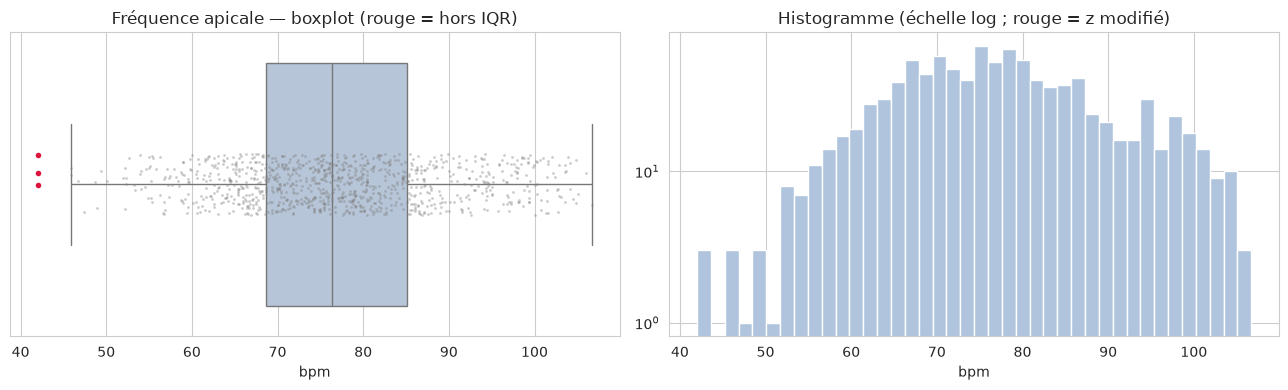

In [19]:
r_apical = anomalies_univariees(obs[obs.observation_code == 'apical'].numeric_value, 'Fréquence apicale', 'bpm')

In [20]:
# Les valeurs hors IQR sont-elles celles que le jeu de données qualifie lui-même de 'review' / 'discordant' ?
ap = obs[obs.observation_code == 'apical'].loc[r_apical.index].assign(hors_IQR=r_apical.IQR)
pd.crosstab(ap.interpretation_code, ap.hors_IQR)

hors_IQR,False,True
interpretation_code,,
discordant,109,0
within_expected_range,905,3


### 3.3 Anomalies multivariées
On reconstruit **une ligne par consultation** avec les 4 mesures cardio-respiratoires (pouls au repos, pouls périphérique, fréquence apicale, saturation) et l'écart apical − périphérique. On compare ensuite les méthodes aux observations étiquetées `discordant`.

(1017, 5)
Observations cardio : n=1017 | Isolation Forest : 51 | LOF : 51 | DBSCAN (eps=1.44, min_samples=8) : 2
  Flaggés par >= 2 méthodes : 21 | par les 3 : 2


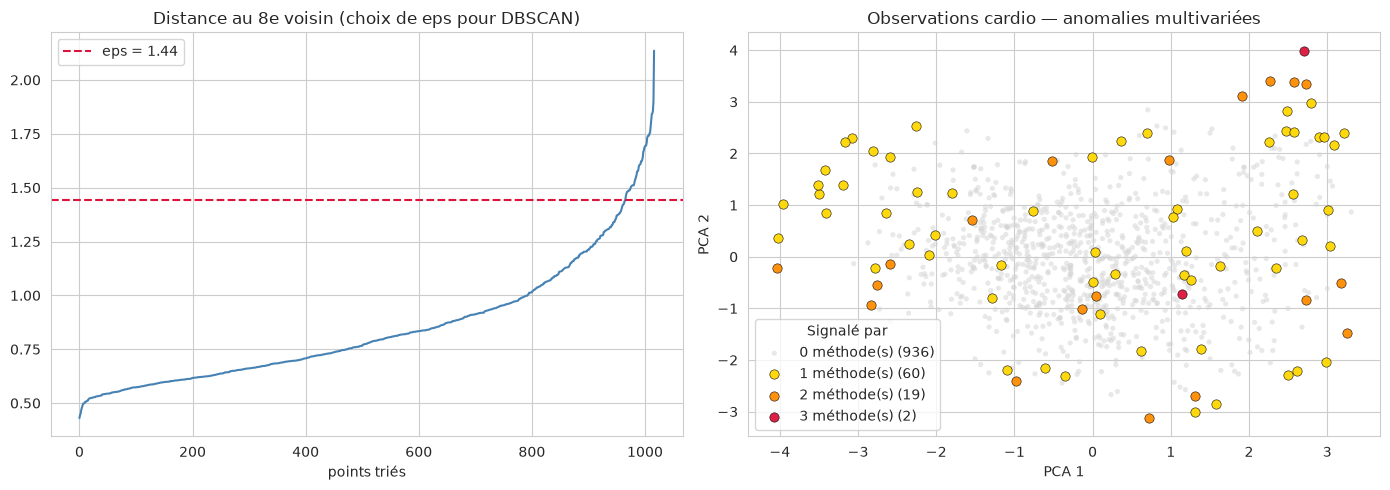

In [21]:
large = (obs[obs.observation_code.isin(['rpulse', 'ppulse', 'apical', 'o2sat'])]
         .pivot_table(index='encounter_number', columns='observation_code', values='numeric_value', aggfunc='mean').dropna())
large['ecart_apical_ppulse'] = large.apical - large.ppulse
print(large.shape)
m_obs = anomalies_multivariees(large, 'Observations cardio', contamination=0.05, n_voisins=30, min_samples=8)

In [22]:
# Confrontation avec l'étiquette 'discordant' (portée par la ligne apicale de la consultation)
disc = obs[(obs.observation_code == 'apical')].set_index('encounter_number').interpretation_code.reindex(large.index)
m_obs['discordant'] = (disc == 'discordant').values
print('Consultations discordantes :', m_obs.discordant.sum(), 'sur', len(m_obs))
for meth in ['IsolationForest', 'LOF', 'DBSCAN']:
    tp = (m_obs[meth] & m_obs.discordant).sum()
    print(f'{meth:16s} signalées : {m_obs[meth].sum():4d} | dont discordantes : {tp:3d} | rappel : {tp / m_obs.discordant.sum():.2f}')
print()
print(large.assign(discordant=m_obs.discordant).groupby('discordant').mean().round(1))

Consultations discordantes : 109 sur 1017
IsolationForest  signalées :   51 | dont discordantes :  17 | rappel : 0.16
LOF              signalées :   51 | dont discordantes :  13 | rappel : 0.12
DBSCAN           signalées :    2 | dont discordantes :   1 | rappel : 0.01

observation_code  apical  o2sat  ppulse  rpulse  ecart_apical_ppulse
discordant                                                          
False               75.0   97.0    73.2    73.9                  1.7
True                94.6   97.2    72.1    72.2                 22.5


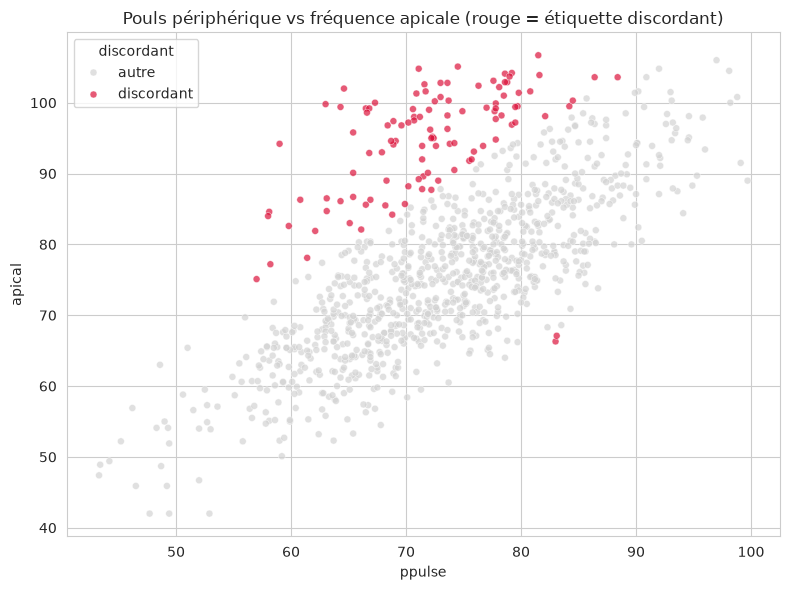

In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=large.assign(discordant=m_obs.discordant.map({True: 'discordant', False: 'autre'})), x='ppulse', y='apical', hue='discordant', palette={'autre': 'lightgrey', 'discordant': 'crimson'}, s=25, alpha=0.7)
plt.title('Pouls périphérique vs fréquence apicale (rouge = étiquette discordant)')
plt.tight_layout(); plt.show()

**Interprétation :**
- **Par type de mesure** : les proportions hors IQR sont faibles (≤ 6.25 % : `lefteye` 15/240, `idcons` 12/240, `righteye` 11/240...). Ce sont surtout des queues de scores bornés à 100, pas des erreurs. Pour la **fréquence apicale** : 3 valeurs hors IQR sur 1 017, aucune par z-score ni z modifié, et ces 3 sont toutes `within_expected_range`.
- **Les 109 observations `discordant` ne sont pas des valeurs aberrantes univariées** : aucune n'est hors IQR. Elles le deviennent en regardant deux mesures ensemble : l'écart moyen apicale − pouls périphérique est de **22.5 bpm** pour les consultations discordantes contre **1.7 bpm** pour les autres (fréquence apicale moyenne 94.6 contre 75.0, pouls périphérique identique : 72.1 contre 73.2). Le nuage rouge du graphique est décalé vers le haut.
- **Multivarié** (1 017 consultations, 5 variables) : Isolation Forest 51, LOF 51, DBSCAN 2 ; 21 signalées par au moins 2 méthodes, 2 par les 3. Rappel sur les discordantes : Isolation Forest 17/109 (0.16), LOF 13/109 (0.12), DBSCAN 1/109. Les discordantes forment 10.7 % des consultations : c'est un groupe **trop dense pour être « rare »**, donc les méthodes non supervisées avec un taux de contamination de 5 % le manquent presque.

**Est-ce vraiment une anomalie ?** Oui, mais d'un autre type : une **anomalie contextuelle** (fréquence apicale incohérente avec le pouls périphérique), pas une valeur extrême. Elle est déjà marquée par l'étiquette `discordant` du jeu de données et n'est pas un bruit de mesure (le pouls périphérique reste normal). C'est la piste principale de ce fichier pour le bloc 7.

---
## 4. `clinical_procedures`

In [24]:
proc = pd.read_csv(chemin + 'clinical_procedures_cleaned.csv', parse_dates=['scheduled_time', 'performed_time', 'next_review_date'])
proc['retard_min'] = (proc.performed_time - proc.scheduled_time).dt.total_seconds() / 60
proc['delai_revue_j'] = (proc.next_review_date - proc.performed_time.dt.normalize()).dt.days
print(proc.shape)
proc[['retard_min', 'delai_revue_j']].describe().round(2)

(310, 16)


,retard_min,delai_revue_j
count,310.00,254.00
mean,1110.61,339.94
std,15244.13,190.45
min,10.00,28.00
25%,10.00,173.25
50%,10.00,363.00
75%,10.00,472.00
max,254890.00,807.00


### 4.1 Patterns (Apriori)

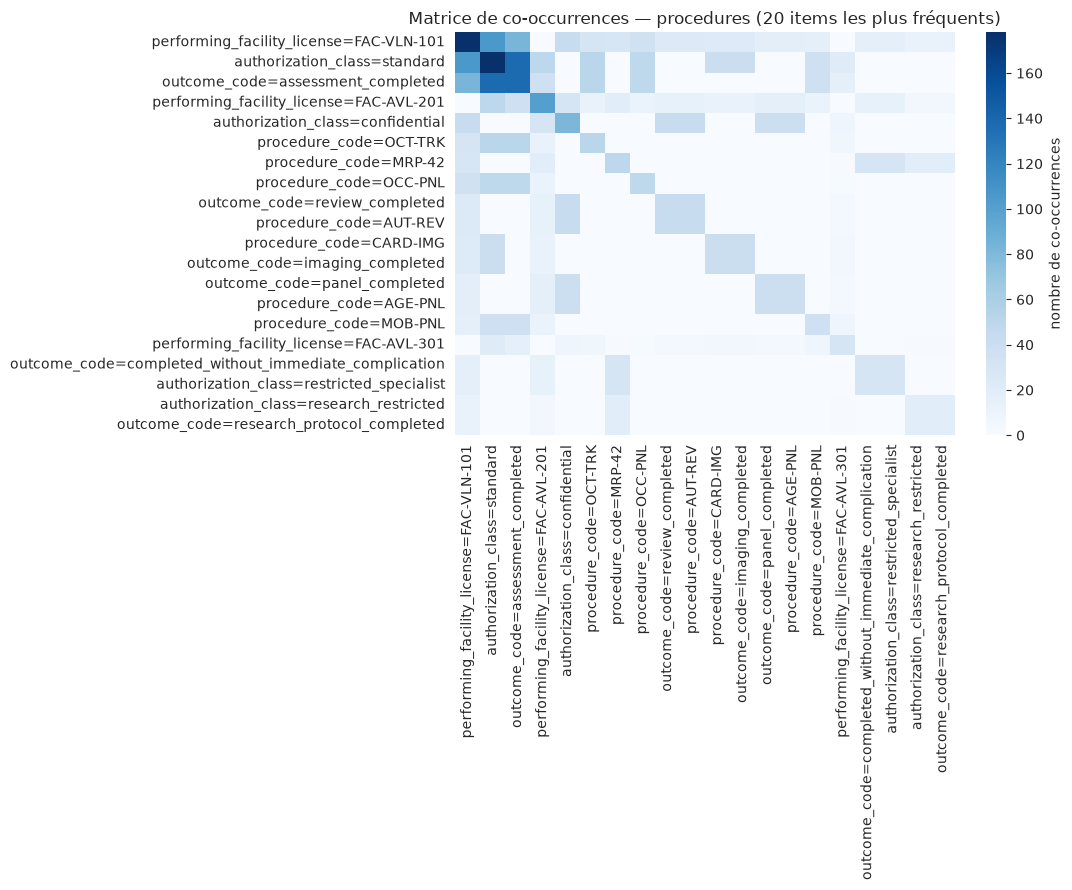

105 itemsets fréquents (support >= 0.05) dont 85 de taille >= 2
138 règles avec confidence >= 0.7 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage
0,authorization_class=research_restricted,outcome_code=research_protocol_completed,0.065,1.0,15.500,0.060
1,outcome_code=research_protocol_completed,authorization_class=research_restricted,0.065,1.0,15.500,0.060
2,authorization_class=research_restricted & proc...,outcome_code=research_protocol_completed,0.065,1.0,15.500,0.060
3,outcome_code=research_protocol_completed & pro...,authorization_class=research_restricted,0.065,1.0,15.500,0.060
4,authorization_class=research_restricted,outcome_code=research_protocol_completed & pro...,0.065,1.0,15.500,0.060
5,outcome_code=research_protocol_completed,authorization_class=research_restricted & proc...,0.065,1.0,15.500,0.060
6,outcome_code=completed_without_immediate_compl...,authorization_class=restricted_specialist,0.097,1.0,10.333,0.087
7,authorization_class=restricted_specialist,outcome_code=completed_without_immediate_compl...,0.097,1.0,10.333,0.087
8,authorization_class=restricted_specialist & pr...,outcome_code=completed_without_immediate_compl...,0.097,1.0,10.333,0.087
9,outcome_code=completed_without_immediate_compl...,authorization_class=restricted_specialist,0.097,1.0,10.333,0.087


dont 14 règles non déterministes (confidence < 0.99) :


,antecedents,consequents,support,confidence,lift,leverage
84,procedure_code=OCC-PNL,outcome_code=assessment_completed & performing...,0.113,0.714,2.668,0.071
85,authorization_class=standard & procedure_code=...,outcome_code=assessment_completed & performing...,0.113,0.714,2.668,0.071
86,procedure_code=OCC-PNL,authorization_class=standard & outcome_code=as...,0.113,0.714,2.668,0.071
105,procedure_code=OCC-PNL,authorization_class=standard & performing_faci...,0.113,0.714,2.089,0.059
106,outcome_code=assessment_completed & procedure_...,authorization_class=standard & performing_faci...,0.113,0.714,2.089,0.059
107,authorization_class=standard & performing_faci...,outcome_code=assessment_completed,0.268,0.783,1.772,0.117
108,authorization_class=standard & performing_faci...,outcome_code=assessment_completed,0.055,0.773,1.749,0.023
131,authorization_class=standard,outcome_code=assessment_completed,0.442,0.770,1.742,0.188
132,authorization_class=standard & performing_faci...,outcome_code=assessment_completed,0.119,0.740,1.674,0.048
133,procedure_code=OCC-PNL,performing_facility_license=FAC-VLN-101,0.113,0.714,1.244,0.022


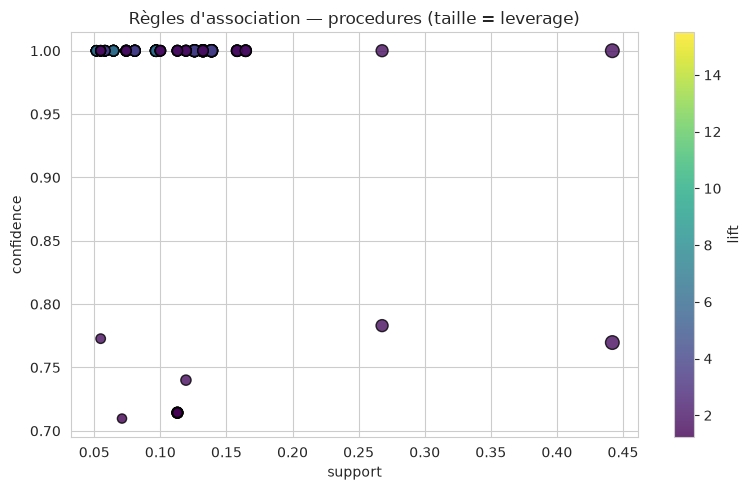

In [25]:
cat_proc = ['procedure_code', 'authorization_class', 'outcome_code', 'performing_facility_license']
onehot_proc, freq_proc, regles_proc = patterns(proc[cat_proc], min_support=0.05, nom='procedures', min_conf=0.7, min_lift=1.2)

**Interprétation :** 105 itemsets fréquents, 138 règles. Les règles de lift le plus élevé sont déterministes et correspondent aux 50 procédures isolées du bloc 2 :
- `authorization_class=research_restricted` ⇔ `outcome_code=research_protocol_completed` ⇔ `MRP-42` (support 0.065 = 20 procédures, confidence 1, **lift 15.5**).
- `authorization_class=restricted_specialist` ⇔ `completed_without_immediate_complication` ⇔ `MRP-42` (support 0.097 = 30 procédures, confidence 1, **lift 10.3**).

Règles non déterministes : `OCC-PNL` ⇒ `assessment_completed` & `FAC-VLN-101` (confidence 0.71, lift 2.67) ; `authorization_class=standard` ⇒ `assessment_completed` (confidence 0.77, lift 1.74, support 0.44). Les procédures `MRP-42` apparaissent donc comme un **bloc à part**, avec ses propres issues (`research_protocol_completed`, `completed_without_immediate_complication`) qu'aucune autre procédure n'utilise.

### 4.2 Anomalies univariées
Le retard est identique (10 min) pour presque toutes les procédures : l'IQR vaut 0 et la MAD aussi. C'est un cas où les méthodes classiques se dégradent (voir interprétation).

Retard (réalisé − planifié) : n=310, médiane=10.00, Q1=10.00, Q3=10.00, min=10.00, max=254890.00
  IQR : 52 | z-score (|z|>3) : 2 | z modifié (>3.5) : 2 (MAD = 0 : repli sur l'écart moyen absolu)


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


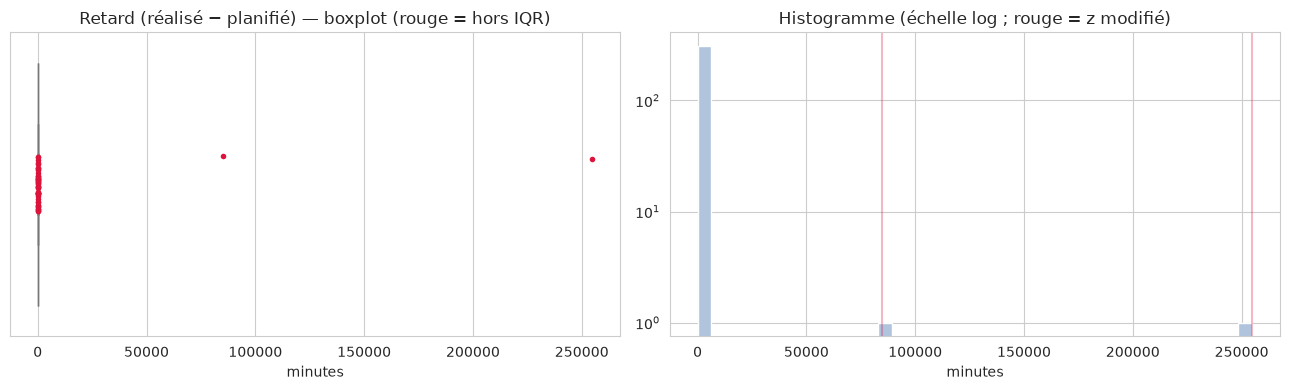

Délai avant revue : n=254, médiane=363.00, Q1=173.25, Q3=472.00, min=28.00, max=807.00
  IQR : 0 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


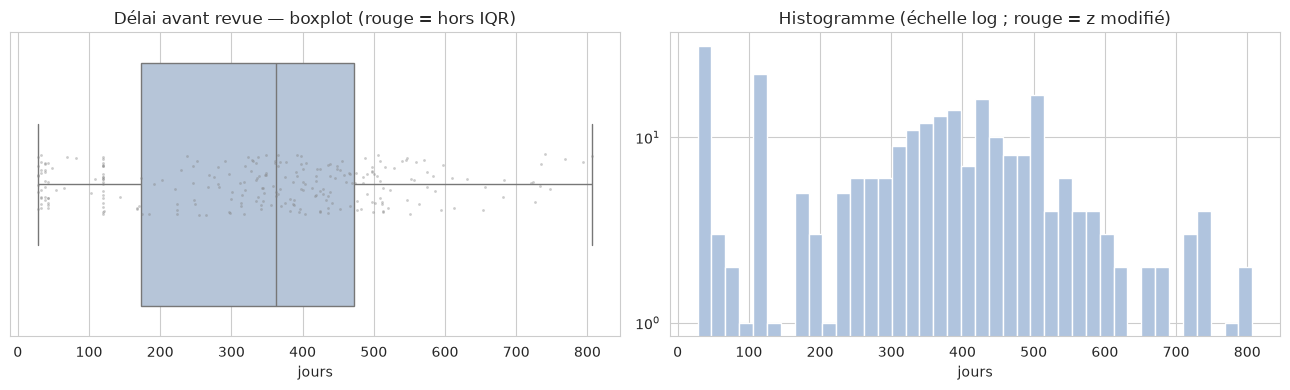

,procedure_record_id,patient_number,procedure_code,scheduled_time,performed_time,retard_min
53,PRC-000054,PAT-31042,OCT-TRK,2021-06-08 09:35:00,2021-08-06 09:45:00,84970.0
70,PRC-000071,PAT-31227,AUT-REV,2021-06-12 12:35:00,2021-12-06 12:45:00,254890.0


In [26]:
r_retard = anomalies_univariees(proc.retard_min, 'Retard (réalisé − planifié)', 'minutes')
r_revue = anomalies_univariees(proc.delai_revue_j, 'Délai avant revue', 'jours')
proc.loc[r_retard[r_retard.flag_z | r_retard.flag_zm].index, ['procedure_record_id', 'patient_number', 'procedure_code', 'scheduled_time', 'performed_time', 'retard_min']].sort_values('retard_min')

In [27]:
# Les 52 valeurs « hors IQR » : en réalité 3 valeurs de retard (10, 35, 40 min) liées à la classe d'autorisation
pd.crosstab(proc.authorization_class, proc.retard_min.where(proc.retard_min < 100).astype('Int64').astype(str).replace('<NA>', '> 100 (extrême)'))

retard_min,10,35,40
authorization_class,,,
confidential,81,0,0
research_restricted,0,0,20
restricted_specialist,0,30,0
standard,177,0,0


### 4.3 Anomalies multivariées

Procedures : n=254 | Isolation Forest : 8 | LOF : 8 | DBSCAN (eps=0.14, min_samples=5) : 5
  Flaggés par >= 2 méthodes : 3 | par les 3 : 1


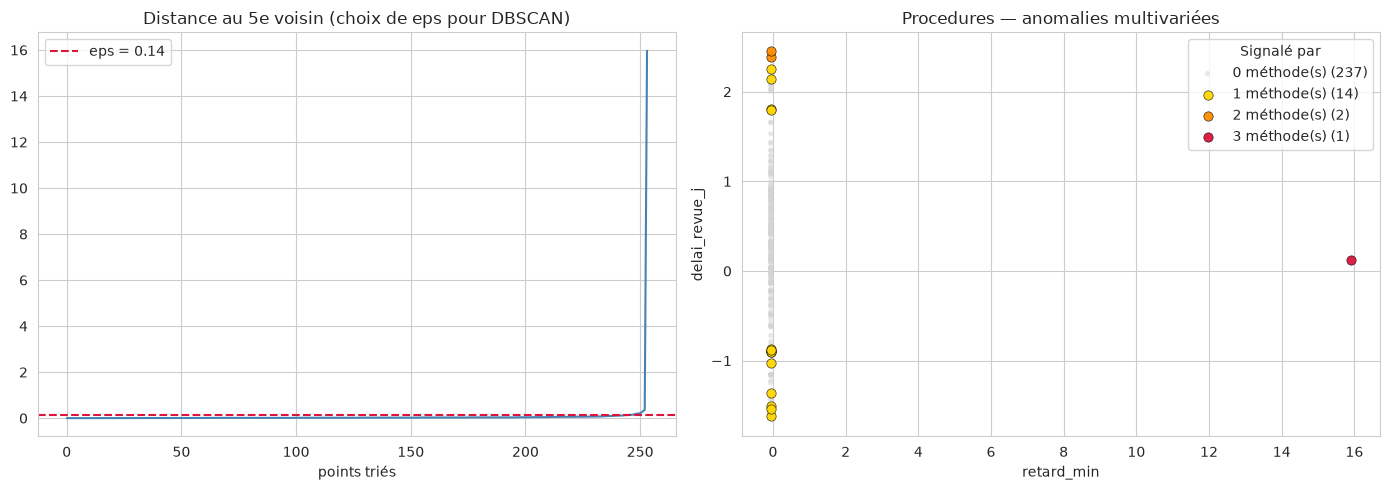

,procedure_record_id,procedure_code,retard_min,delai_revue_j,nb_methodes,score_if
53,PRC-000054,OCT-TRK,84970.0,363.0,3,0.868536
221,PRC-000222,CARD-IMG,10.0,807.0,2,0.674121
241,PRC-000242,OCT-TRK,10.0,33.0,1,0.646064
190,PRC-000191,OCC-PNL,10.0,794.0,2,0.642456
98,PRC-000099,OCC-PNL,10.0,769.0,1,0.626266
270,PRC-000271,CARD-IMG,10.0,48.0,1,0.588319
209,PRC-000210,OCT-TRK,10.0,747.0,1,0.578139
99,PRC-000100,AUT-REV,10.0,54.0,1,0.576536
115,PRC-000116,OCT-TRK,10.0,683.0,1,0.574860
129,PRC-000130,AGE-PNL,10.0,682.0,1,0.574860


In [28]:
X_proc = proc[['retard_min', 'delai_revue_j']].dropna()
m_proc = anomalies_multivariees(X_proc, 'Procedures', contamination=0.03, n_voisins=20, min_samples=5)
proc.loc[m_proc.index, ['procedure_record_id', 'procedure_code', 'retard_min', 'delai_revue_j']].join(m_proc[['nb_methodes', 'score_if']]).sort_values('score_if', ascending=False).head(10)

**Interprétation :**
- **Retard (réalisé − planifié).** 258 procédures sur 310 ont exactement 10 min de retard ; **30 ont 35 min (toutes `restricted_specialist`)**, **20 ont 40 min (toutes `research_restricted`)**, et **2 ont un retard extrême** : PRC-000054 (84 970 min, soit 59 jours ; PAT-31042, `OCT-TRK`, réalisée le 2021-08-06) et PRC-000071 (254 890 min, soit 177 jours ; PAT-31227, `AUT-REV`, réalisée le 2021-12-06). Comme IQR = 0 et MAD = 0, l'IQR signale **52** lignes (tout ce qui n'est pas 10 min) : la méthode se dégrade quand la plupart des valeurs sont identiques. Le z-score et le z modifié (avec repli sur l'écart moyen absolu) isolent proprement les 2 retards extrêmes.
- **Délai avant revue** (254 procédures ont une date de revue) : aucune anomalie par les 3 méthodes univariées.
- **Multivarié** (retard, délai de revue ; 254 lignes) : Isolation Forest 8, LOF 8, DBSCAN 5 ; PRC-000054 est la seule signalée par les 3 méthodes. PRC-000071 **n'apparaît pas** ici car elle n'a pas de date de revue (ligne retirée par `dropna`) : c'est une limite de l'approche multivariée.

**Est-ce vraiment une anomalie ?** Les retards de 35 et 40 min sont une **signature de classe** (une constante par type d'autorisation), pas des erreurs : ils recoupent les 50 `MRP-42` des blocs 2 et 3. Les 2 retards de 59 et 177 jours sont en revanche de **vraies anomalies** : un retard de plusieurs mois entre l'heure planifiée et l'heure réalisée est incompatible avec un retard opérationnel ; soit la date planifiée soit la date de réalisation est fausse, soit la procédure a été replanifiée sans mise à jour. Piste à garder (voir le tableau final).

---
## 5. `patient_administration`
Les noms, prénoms et professions (texte libre) sont exclus.

In [29]:
pat = pd.read_csv(chemin + 'patient_administration_cleaned.csv', parse_dates=['date_of_birth', 'registration_date'])
pat['age_inscription'] = (pat.registration_date - pat.date_of_birth).dt.days / 365.25
pat['annee_inscription'] = pat.registration_date.dt.year + pat.registration_date.dt.dayofyear / 365.25
print(pat.shape)
pat[['age_inscription', 'annee_inscription']].describe().round(2)

(240, 12)


,age_inscription,annee_inscription
count,240.00,240.00
mean,48.72,2019.32
std,15.80,1.58
min,15.27,2014.00
25%,36.11,2018.07
50%,47.97,2019.25
75%,61.55,2020.75
max,79.51,2021.84


### 5.1 Patterns (Apriori)

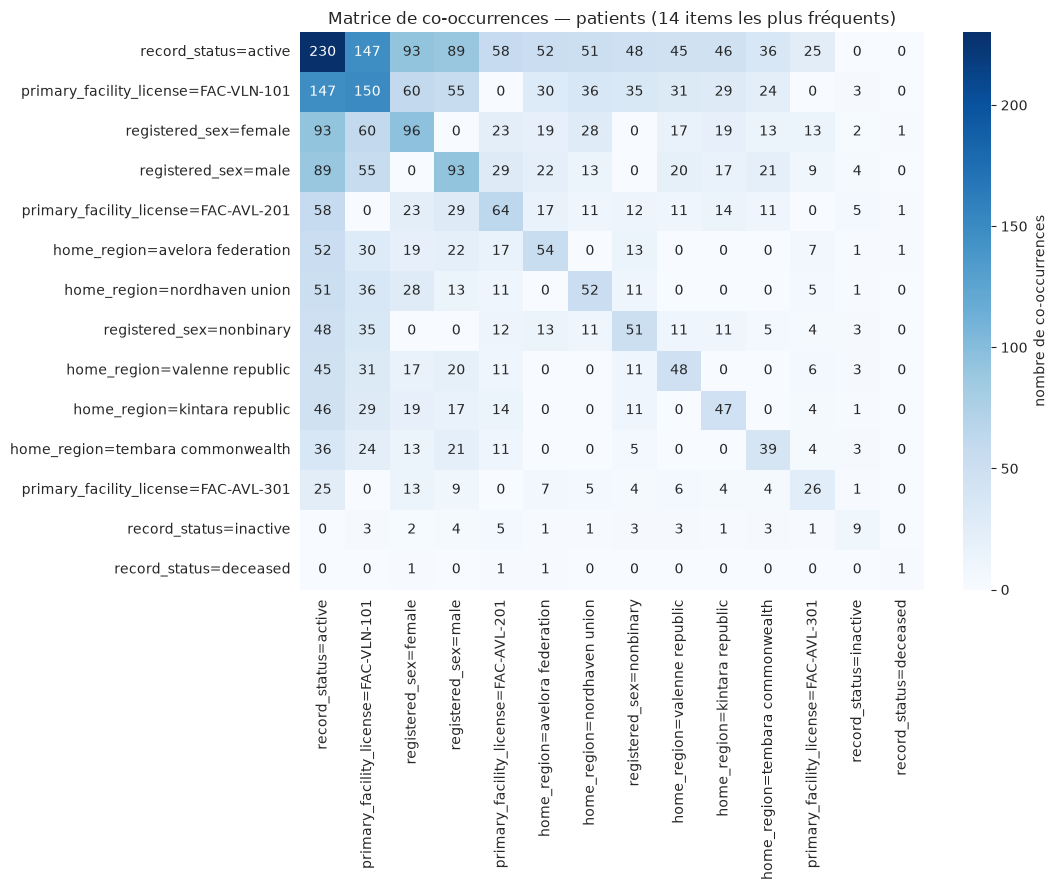

80 itemsets fréquents (support >= 0.05) dont 68 de taille >= 2
0 règles avec confidence >= 0.6 et lift >= 1.2


,antecedents,consequents,support,confidence,lift,leverage


dont 0 règles non déterministes (confidence < 0.99) :


,antecedents,consequents,support,confidence,lift,leverage


In [30]:
cat_pat = ['registered_sex', 'home_region', 'primary_facility_license', 'record_status']
onehot_pat, freq_pat, regles_pat = patterns(pat[cat_pat], min_support=0.05, nom='patients', min_conf=0.6, min_lift=1.2)

**Interprétation :** 80 itemsets fréquents mais **aucune règle** avec confidence ≥ 0.6 et lift ≥ 1.2. Sexe, région, établissement et statut du dossier sont à peu près indépendants (statut `active` pour 230 patients sur 240, ce qui aplatit tout lift). Résultat cohérent avec le bloc 2 : pas de structure dans ce fichier.

### 5.2 Anomalies univariées

Âge à l'inscription : n=240, médiane=47.97, Q1=36.11, Q3=61.55, min=15.27, max=79.51
  IQR : 0 | z-score (|z|>3) : 0 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


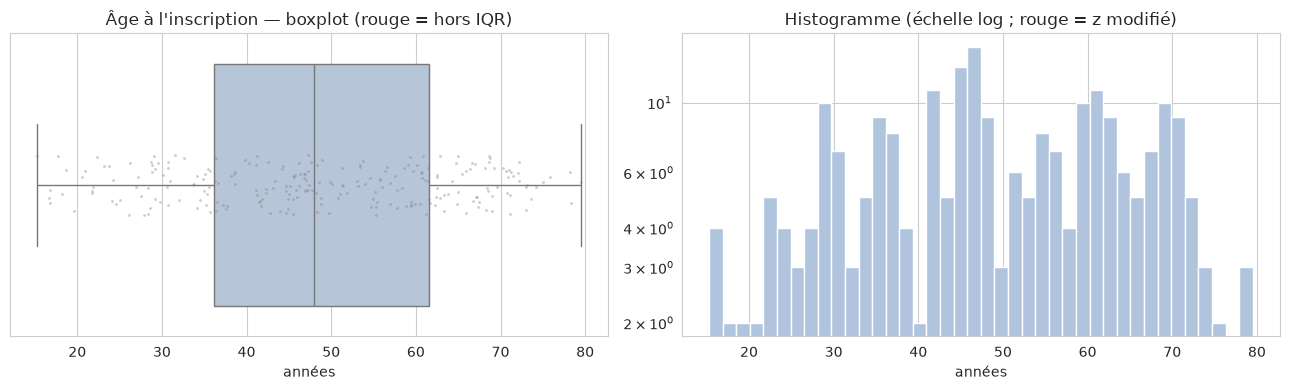

Année d'inscription : n=240, médiane=2019.25, Q1=2018.07, Q3=2020.75, min=2014.00, max=2021.84
  IQR : 1 | z-score (|z|>3) : 1 | z modifié (>3.5) : 0


/home/mariam/.pyenv/versions/3.12.2/lib/python3.12/site-packages/seaborn/categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


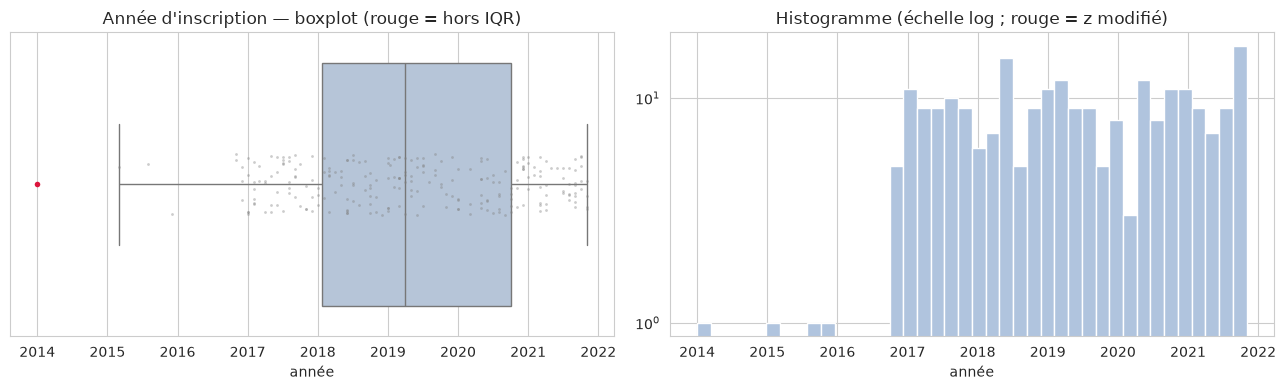

In [31]:
r_age = anomalies_univariees(pat.age_inscription, 'Âge à l\'inscription', 'années')
r_ins = anomalies_univariees(pat.annee_inscription, 'Année d\'inscription', 'année')

### 5.3 Anomalies multivariées

Patients : n=240 | Isolation Forest : 8 | LOF : 8 | DBSCAN (eps=0.60, min_samples=5) : 4
  Flaggés par >= 2 méthodes : 7 | par les 3 : 3


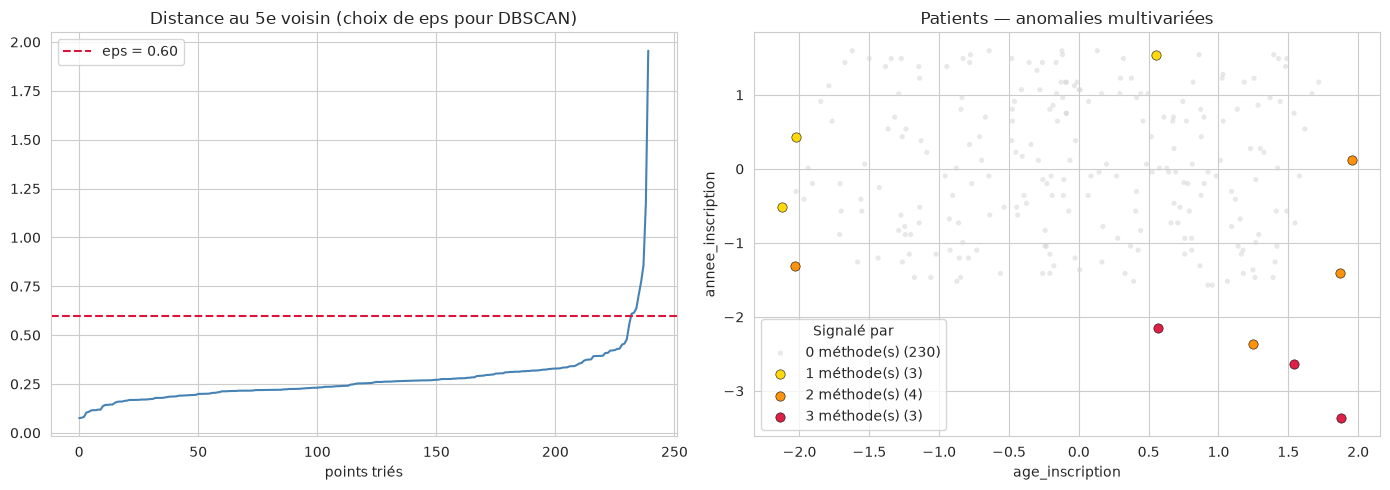

,patient_number,registered_sex,record_status,occupation_text,age_inscription,annee_inscription,nb_methodes,score_if
17,PAT-31099,female,deceased,retired political intermediary and former coun...,78.3,2014.0,3,0.8
12,PAT-31174,male,active,regional governor in the tembara commonwealth,73.0,2015.2,3,0.7
74,PAT-31016,nonbinary,active,research assistant,79.5,2019.5,2,0.6
110,PAT-31100,nonbinary,active,transport worker,16.7,2017.2,2,0.6
15,PAT-31183,female,active,executive director of ardena capital union,57.7,2015.9,3,0.6
178,PAT-31063,male,active,small-business owner,16.8,2020.0,1,0.6
169,PAT-31132,nonbinary,active,teacher,15.3,2018.5,1,0.6
227,PAT-31206,male,active,teacher,78.2,2017.1,2,0.6


In [32]:
X_pat = pat[['age_inscription', 'annee_inscription']].dropna()
m_pat = anomalies_multivariees(X_pat, 'Patients', contamination=0.03, n_voisins=20, min_samples=5)
pat.loc[m_pat.index, ['patient_number', 'registered_sex', 'record_status', 'occupation_text', 'age_inscription', 'annee_inscription']].join(m_pat[['nb_methodes', 'score_if']]).sort_values('score_if', ascending=False).head(8).round(1)

**Interprétation :**
- **Univarié** : âge à l'inscription de 15.3 à 79.5 ans, aucune valeur hors IQR ni par z-score. Pour l'année d'inscription, 1 valeur hors IQR et 1 par z-score (PAT-31099, inscrit en 2014 ; les autres : 8 patients inscrits en 2015-2016 et 231 de 2017 à 2021).
- **Multivarié** (âge, année d'inscription) : Isolation Forest 8, LOF 8, DBSCAN 4 ; 7 patients signalés par au moins 2 méthodes. Les **3 signalés par les 3 méthodes** : PAT-31099 (femme, 78 ans à l'inscription en 2014, seul dossier `deceased`), PAT-31174 (homme, 73 ans, inscrit en 2015, profession « regional governor ») et PAT-31183 (femme, 58 ans, inscrite en 2015, « executive director »). Signalés par 2 méthodes : PAT-31016 (79.5 ans, le plus âgé), PAT-31100 (16.7 ans, l'un des plus jeunes) et PAT-31206 (78 ans).

**Est-ce vraiment une anomalie ?** Ces patients sont **plausibles** (âges réalistes), seulement rares : inscrits tôt (avant 2017) ou aux âges extrêmes. Le point notable est que les trois plus isolés sont des dossiers anciens dont la profession relève de la direction ou de la politique. C'est une **piste à croiser avec les autres domaines** (bloc 7), pas une erreur à corriger. Aucun dossier n'est à supprimer.

---
## 6. Synthèse — ce qui sert au bloc 7 (tableau d'indices)

| Fichier | Observation | Méthode | Hypothèse | Nature |
|---|---|---|---|---|
| `clinical_encounters` | 50 consultations de durée fixe (180 min recherche, 240 min spécialisée), toutes restreintes | IQR / z modifié, Apriori | Elles correspondent au programme `MRP-42` | **Indice** |
| `clinical_procedures` | Règles de lift 15.5 et 10.3 : `research_restricted` et `restricted_specialist` ne partagent aucune issue avec les autres procédures ; retards constants 35 et 40 min | Apriori, IQR | Les 50 `MRP-42` suivent un protocole à part (cf. bloc 2) | **Indice** |
| `clinical_procedures` | PRC-000054 (59 j) et PRC-000071 (177 j) de retard | z modifié, Isolation Forest, LOF | Date erronée ou replanification, à croiser avec les patients PAT-31042 et PAT-31227 | À vérifier |
| `clinical_observation` | 109 observations `discordant` (apicale ≈ +22 bpm vs pouls périphérique), invisibles en univarié | Écart apical − pouls périphérique, Isolation Forest, LOF | Deux sources cardiaques distinctes chez certains patients (cf. notes d'imagerie) | **Indice principal** |
| `clinical_notes` | 8 notes sur 30 datées avant leur consultation ; CLN-510126 à +2 670 j | Délai note − consultation, IQR | Rattachement ou dates approximatifs | **Incohérence de données** |
| `patient_administration` | PAT-31099, PAT-31174, PAT-31183 : dossiers anciens (2014-2015) et professions dirigeantes ou politiques | Isolation Forest, LOF, DBSCAN | Patients à statut particulier, à croiser avec les autres domaines | Piste |

**Pistes abandonnées** : aucune règle d'association exploitable sur `patient_administration` ; les anomalies de longueur de texte (notes) et de délai avant revue (procédures) n'ont rien donné ; les valeurs extrêmes des scores bornés (`lefteye`, `idcons`...) sont des queues de distribution, pas des anomalies.